# Task 2 · Overfitting
The Task 1 CNN against a larger CNN (1.5× wider convolutions, 2× wider FC layer, 2.9× the parameters) and the smaller
CNN of the search, all trained with the same 5 folds and schedule as in Task 1; then the large CNN with dropout, and
separately with weight decay on its FC layers.

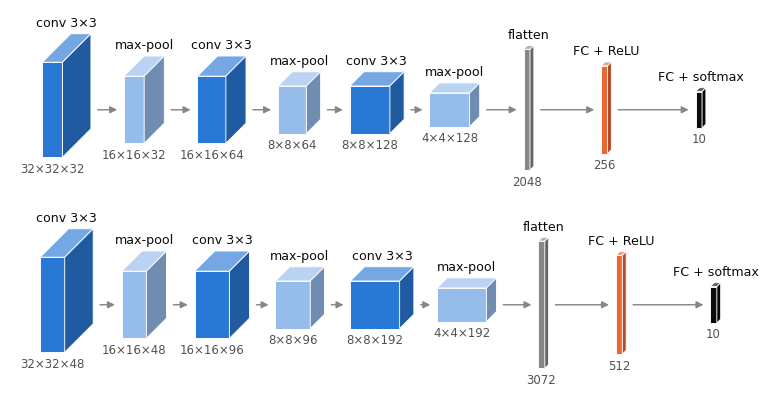

In [1]:
from hw3 import *

B = json.load(open(BEST))['cnn']
large = dict(model=partial(CNN, 48, 512), lr=B['lr'])
S = {'small': dict(model=partial(CNN, 16), lr=B['lr']), 'base': dict(model=partial(CNN, B['arch']), lr=B['lr']),
     'large': large, 'dropout': large | dict(model=partial(CNN, 48, 512, .5)), 'wd': large | dict(wd=.5)}
key = {'small': f"cnn_16-32-64_{B['lr']:g}", 'base': B['key'], 'large': 'large', 'dropout': 'large_dropout', 'wd': 'large_fcwd'}
R = cv({key[k]: S[k] for k in S})
R = {k: R[key[k]] for k in S}
diagram('arch_large', [cnn_layers(B['arch']), cnn_layers(48, 512)])

Overfitting begins at the epoch with the lowest validation loss: after it the validation loss rises while the training
loss keeps falling.

In [2]:
best = {k: np.array([r['val_loss'].argmin().item() + 1 for r in R[k]]) for k in R}
rise = {k: [100 * (r['val_loss'][-1] / r['val_loss'].min() - 1).item() for r in R[k]] for k in R}
pd.DataFrame(best, index=[f'fold {f + 1}' for f in range(FOLDS)])

,small,base,large,dropout,wd
fold 1,8,7,8,10,10
fold 2,9,8,8,10,10
fold 3,8,9,8,10,9
fold 4,9,7,8,10,10
fold 5,8,9,7,10,9


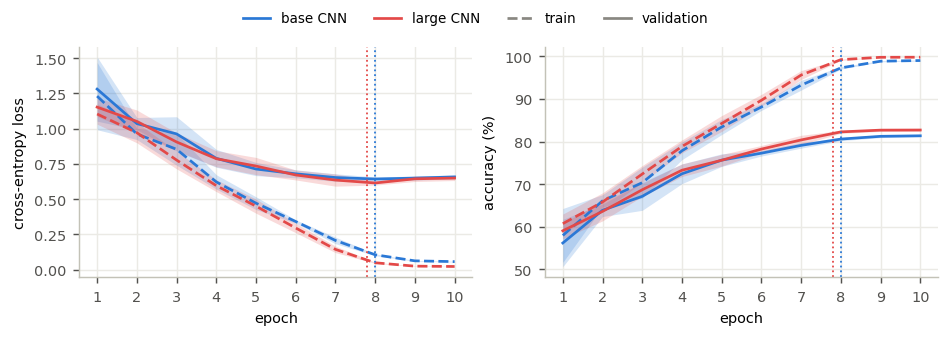

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.5))
G = {'base CNN': ('base', COL['cnn']), 'large CNN': ('large', COL['large'])}
curves({k: (R[n], c) for k, (n, c) in G.items()}, axes)
for n, c in G.values():
    for ax in axes:
        ax.axvline(best[n].mean(), color=c, ls=':', lw=1)
save(fig, 'overfit')

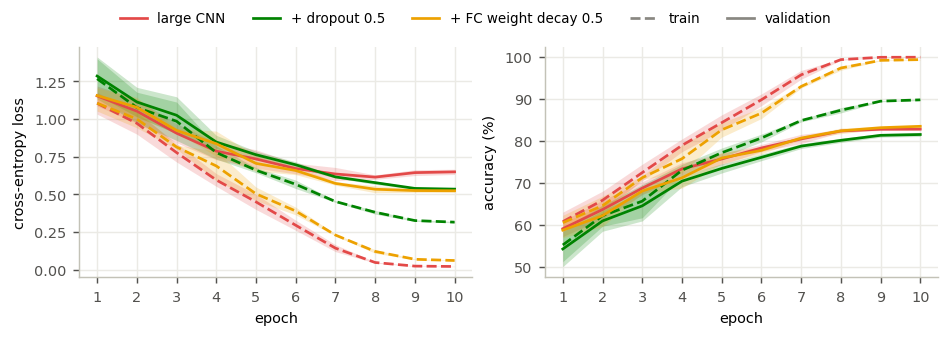

In [4]:
G = {'large CNN': ('large', COL['large']), '+ dropout 0.5': ('dropout', COL['dropout']),
     '+ FC weight decay 0.5': ('wd', COL['wd'])}
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.5))
curves({k: (R[n], c) for k, (n, c) in G.items()}, axes)
save(fig, 'regularize')

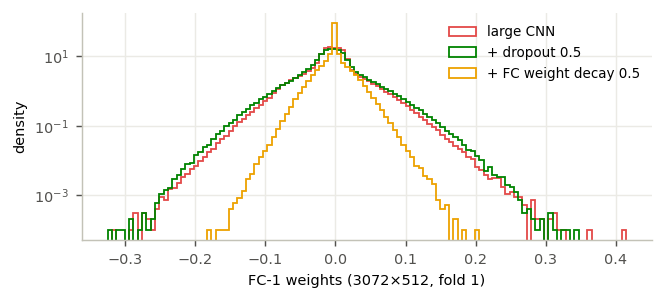

In [5]:
W = {k: load(key[n], S[n]['model'])[5].weight.detach().flatten().numpy() for k, (n, _) in G.items()}
bins = np.histogram_bin_edges(np.concatenate(list(W.values())), 120)
fig, ax = plt.subplots(figsize=(5, 2.2))
for k, (n, c) in G.items():
    ax.hist(W[k], bins, histtype='step', color=c, density=True, label=k)
ax.set(xlabel='FC-1 weights (3072×512, fold 1)', ylabel='density', yscale='log')
ax.legend()
save(fig, 'fc_weights')

In [6]:
T = pd.DataFrame({k: {'params (M)': f"{R[k][0]['params'] / 1e6:.2f}", 'train acc': ms(last(R[k], 'train_acc')),
                      'val acc': ms(last(R[k], 'val_acc')), 'test acc': ms(last(R[k], 'test_acc')),
                      'gap': ms(last(R[k], 'train_acc') - last(R[k], 'val_acc')),
                      'best val loss': ms([r['val_loss'].min().item() for r in R[k]], 1, 3),
                      'final val loss': ms(last(R[k], 'val_loss'), 1, 3), 'best epoch': ms(best[k], 1)} for k in R}).T
rows('t2_table', T.set_axis(['Small CNN', 'Base CNN', 'Large CNN', '+ dropout', '+ FC weight decay']))
tex('t2', **{k + n: v for k in R for n, v in (('Best', T['best epoch'][k]), ('Rise', ms(rise[k], 1)),
                                              ('Test', T['test acc'][k]), ('Gap', T['gap'][k]))})
T

,params (M),train acc,val acc,test acc,gap,best val loss,final val loss,best epoch
small,0.29,95.5 (0.3),78.3 (0.4),77.9 (0.4),17.3 (0.5),0.695 (0.011),0.702 (0.013),8.4 (0.5)
base,0.62,99.1 (0.1),81.4 (0.2),81.0 (0.3),17.7 (0.2),0.640 (0.013),0.658 (0.014),8.0 (1.0)
large,1.79,99.8 (0.1),82.7 (0.3),82.4 (0.2),17.1 (0.3),0.612 (0.021),0.650 (0.017),7.8 (0.4)
dropout,1.79,89.7 (0.2),81.5 (0.5),81.1 (0.3),8.2 (0.4),0.535 (0.006),0.535 (0.006),10.0 (0.0)
wd,1.79,99.3 (0.0),83.4 (0.3),83.0 (0.1),15.9 (0.3),0.524 (0.012),0.525 (0.011),9.6 (0.5)
